# MovieLens-25M EDA

Questions this notebook answers (each one feeds a design decision):
1. Rating distribution → where should the implicit-positive threshold sit?
2. Interactions over time → where do the temporal split cutoffs land?
3. User/item activity long tail → why k-core filtering, and what popularity bias to expect.
4. Genre distribution → which genres go into the top-8 one-hot ranker features.

Run `python -m src.data.download` first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("../data/raw/ml-25m")
ratings = pd.read_csv(RAW / "ratings.csv")
movies = pd.read_csv(RAW / "movies.csv")
print(f"{len(ratings):,} ratings | {ratings.userId.nunique():,} users | {ratings.movieId.nunique():,} movies")
ratings.head()

25,000,095 ratings | 162,541 users | 59,047 movies


,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510


## 1. Rating distribution → implicit threshold

We convert to implicit feedback with `rating >= 4.0` as positive. The histogram shows why: 4.0+ is a clear "liked it" signal, and high-precision positives matter because in-batch negative sampling treats *other users' positives* as negatives — noisy positives poison that.

fraction kept at threshold 4.0: 49.8%


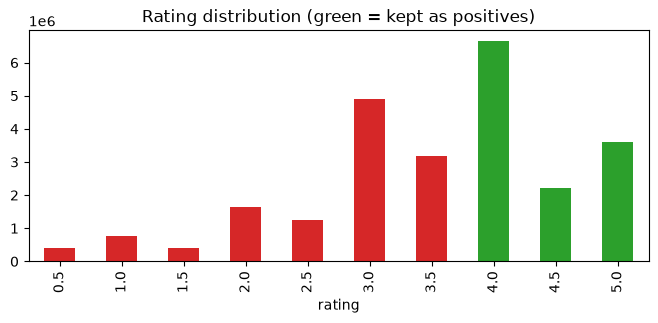

In [2]:
counts = ratings.rating.value_counts().sort_index()
ax = counts.plot.bar(figsize=(8, 3), color=["tab:red" if r < 4.0 else "tab:green" for r in counts.index])
ax.set_title("Rating distribution (green = kept as positives)")
frac = (ratings.rating >= 4.0).mean()
print(f"fraction kept at threshold 4.0: {frac:.1%}")

## 2. Interactions over time → temporal split cutoffs

train|val cutoff (q=0.8): 2016-06-25


val|test cutoff (q=0.9): 2018-01-04


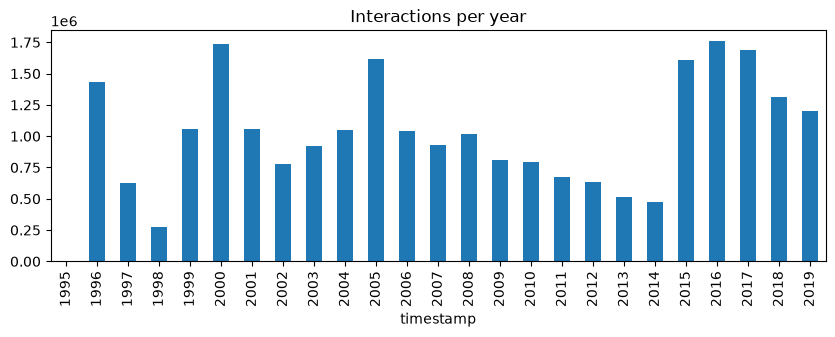

In [3]:
ts = pd.to_datetime(ratings.timestamp, unit="s")
ax = ts.dt.year.value_counts().sort_index().plot.bar(figsize=(10, 3))
ax.set_title("Interactions per year")
for q, label in [(0.8, "train|val"), (0.9, "val|test")]:
    cutoff = pd.to_datetime(ratings.timestamp.quantile(q), unit="s")
    print(f"{label} cutoff (q={q}): {cutoff.date()}")

## 3. Activity long tail → k-core filtering + popularity bias

top-100 movies account for 22.8% of all positives — popularity baseline will be strong


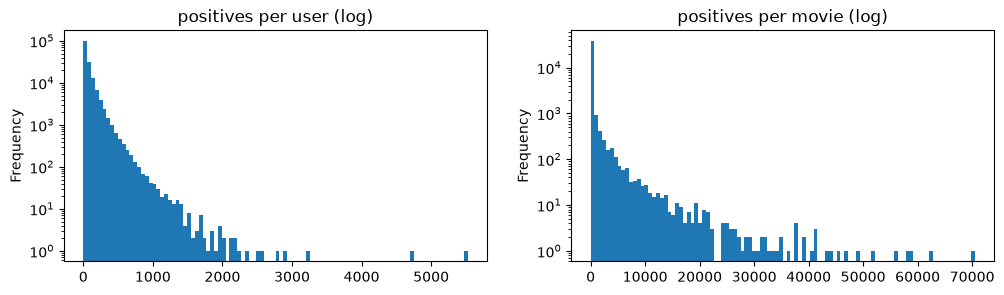

In [4]:
pos = ratings[ratings.rating >= 4.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
pos.userId.value_counts().plot.hist(bins=100, log=True, ax=axes[0], title="positives per user (log)")
pos.movieId.value_counts().plot.hist(bins=100, log=True, ax=axes[1], title="positives per movie (log)")
top100 = pos.movieId.value_counts().head(100).sum() / len(pos)
print(f"top-100 movies account for {top100:.1%} of all positives — popularity baseline will be strong")

## 4. Genres → ranker one-hot features

In [5]:
genre_counts = movies.genres.str.split("|").explode().value_counts()
print(genre_counts)
print(f"\ntop-8 genres for ranker one-hot: {list(genre_counts.head(8).index)}")

genres
Drama                 25606
Comedy                16870
Thriller               8654
Romance                7719
Action                 7348
Horror                 5989
Documentary            5605
Crime                  5319
(no genres listed)     5062
Adventure              4145
Sci-Fi                 3595
Children               2935
Animation              2929
Mystery                2925
Fantasy                2731
War                    1874
Western                1399
Musical                1054
Film-Noir               353
IMAX                    195
Name: count, dtype: int64

top-8 genres for ranker one-hot: ['Drama', 'Comedy', 'Thriller', 'Romance', 'Action', 'Horror', 'Documentary', 'Crime']
